# 4. The state system

In this notebook, we introduce the state system of the planner: four
operational modes, and a cost for each change of mode. Without it, the planner
uses the four-wheel-steering controls wherever they are cheaper, including in
open space, where crab motion brings no benefit and unsettles the people
working nearby.

**Summary**

1. [What the mode structure is for](#1)
2. [The four modes](#2)
3. [Transition costs](#3)
4. [The extended equation](#4)
5. [Where the modes are used](#5)

In [1]:
import sys, os, json
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D

from shfm import DEFAULT_VEHICLE
from shfm.figures import save

plt.rcParams.update({"figure.dpi": 110, "font.size": 11})

from shfm import (from_benchmark_run, Planner, REFERENCE_COEFFICIENTS,
                  SOLVER_ORDER, THESIS_ORDER)
from shfm import benchmark as B
from shfm.kinematics import control_set, control_set_unstructured
from shfm.states import transition_matrix
from shfm.postprocess import dechatter
from shfm.splice import close_start
from shfm.plotting import draw_map, draw_path, draw_footprints, draw_pose, STATE_COLORS


def evenly(path, n):
    "Indices of n points of a path, evenly spaced along its length."
    arc = np.r_[0, np.cumsum(np.hypot(*np.diff(path[:, :2], axis=0).T))]
    return np.searchsorted(arc, np.linspace(0, arc[-1], n)).clip(0, len(path) - 1)

<a id='1'></a>
## 1. What the mode structure is for

We first consider a planner given the four-wheel-steering controls and nothing
else, which crabs wherever crabbing is even marginally cheaper. This is the
baseline the state system improves on: a single state carrying the eight
extreme steering vectors, forward and backward, every control at the same
speed and no transition to pay.

The comparison below is the one of figure 4.10 of the thesis, which
`generators/state_system_comparison.py` redraws as `no_state.pdf` and
`with_state.pdf`, on the same scene; the two points on which the printed figure
differs are given below the figure. The scene is
in `data/state_system/`: a 54 by 54 grid at one metre per cell, with a corridor
between a wall on the left and a row of bays. The vehicle starts in the open
on the right, at $(50, 30, \pi/2)$, and ends inside the top bay, at
$(22, 45, 3\pi/2)$. Both planners steer both axles up to 1.05 rad. With the
state system the controls are split into the four modes of section 2, they take
the reference speed coefficients instead of a common unit speed, and every
change of mode costs one unit.

In [2]:
with open("../data/state_system/bays.json") as f:
    run = json.load(f)["runs"][0]
bays = from_benchmark_run(run, zoom=1.0, n_theta=100)
bay_start, bay_goal = run["environment"]["start"], run["environment"]["goal"]
print(bays)

STEERING = 1.05          # saturation of both axles, rad, on both sides
unstructured = lambda th, wb, xp: control_set_unstructured(
    th, wb, delta_f_max=STEERING, delta_r_max=STEERING, xp=xp)
four_modes = lambda th, wb, xp: control_set(
    th, wb, delta_f_max=STEERING, delta_r_max=STEERING, xp=xp, **REFERENCE_COEFFICIENTS)

# One state carrying the eight extreme controls, so there is no transition
# matrix to pass. A zero matrix over two free-switching states is not the same
# thing; see the note in control_set_unstructured.
without = Planner(bays, controls=unstructured).solve(bay_start + [0], [bay_goal + [0]])
# Every change of mode at one unit, as for the thesis figure.
with_states = Planner(bays, controls=four_modes, transitions=np.ones((4, 4)) - np.eye(4)
                      ).solve(bay_start + [0], [bay_goal + [0]])

# The transition costs of section 3 instead, for comparison.
from scipy.spatial import cKDTree
k1050 = Planner(bays, k1=10, k2=50, controls=four_modes).solve(bay_start + [0], [bay_goal + [0]])
print("with k1 = 10, k2 = 50: at most %.2f units from the path above"
      % cKDTree(with_states.path(0)[:, :2]).query(k1050.path(0)[:, :2])[0].max())

Environment(name='grid', shape=(54, 54), n_theta=100, zoom=1.0, 1 unit = 1 m)
with k1 = 10, k2 = 50: at most 0.01 units from the path above


We measure the difference by the *crab angle*: the angle between the heading
and the direction in which the vehicle travels. It stays near zero in a
car-like motion and grows in crab motion. Below, a path crabs where this angle
exceeds 20 degrees, and the share is counted along the length travelled.

In [3]:
def crab_angle(path):
    "Angle between the heading and the direction of travel, per step, and the step lengths."
    step = np.diff(path[:, :2], axis=0)
    length = np.hypot(*step.T)
    course = np.arctan2(step[:, 1], step[:, 0])
    a = np.abs(np.arctan2(np.sin(course - path[:-1, 2]), np.cos(course - path[:-1, 2])))
    a = np.minimum(a, np.pi - a)                  # forward or reverse alike
    a[length < 1e-6] = 0.0
    return a, length


CRAB = np.radians(20)
paths = {"without the state system": without.path(0),
         "with the state system": with_states.path(0)}
for name, p in paths.items():
    a, length = crab_angle(p)
    print("%-25s length %5.1f m, crab angle above 20 deg on %4.1f%% of it"
          % (name, length.sum(), 100 * length[a > CRAB].sum() / length.sum()))

s = with_states.path(0)[:, 3].round().astype(int)
print("\nwith the state system, share of the points in each mode:")
for k, name in enumerate(SOLVER_ORDER):
    print("  %-9s %5.1f%%" % (name, 100 * np.mean(s == k)))

without the state system  length 103.2 m, crab angle above 20 deg on 44.3% of it
with the state system     length  98.8 m, crab angle above 20 deg on  5.3% of it

with the state system, share of the points in each mode:
  nav_fwd   100.0%
  man_fwd     0.0%
  man_bwd     0.0%
  nav_bwd     0.0%


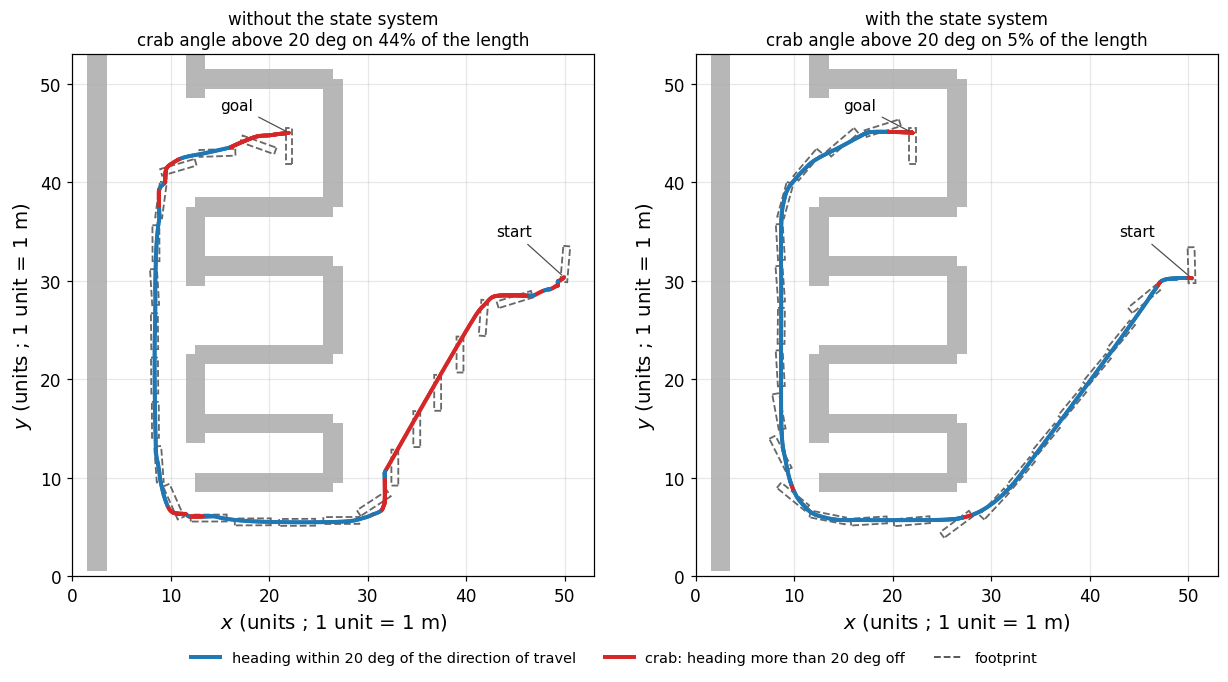

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.8))
for ax, (name, p) in zip(axes, paths.items()):
    a, length = crab_angle(p)
    draw_map(ax, bays)
    steps = np.stack([p[:-1, :2], p[1:, :2]], axis=1)
    ax.add_collection(LineCollection(steps, colors=np.where(a > CRAB, "tab:red", "tab:blue"),
                                     lw=2.6, capstyle="round", zorder=3))
    i = evenly(p, 24)
    draw_footprints(ax, p[i], bays.vehicle, bays.zoom, n=len(i), color="0.3", alpha=0.85)
    for xy, label, where in ((p[0, :2], "start", (43, 34.5)), (p[-1, :2], "goal", (15, 47.3))):
        ax.annotate(label, xy, xytext=where, fontsize=10, zorder=8,
                    arrowprops=dict(arrowstyle="-", color="0.3", lw=0.8))
    ax.set_title("%s\ncrab angle above 20 deg on %.0f%% of the length"
                 % (name, 100 * length[a > CRAB].sum() / length.sum()), fontsize=11)
fig.legend(handles=[Line2D([], [], color="tab:blue", lw=2.6,
                           label="heading within 20 deg of the direction of travel"),
                    Line2D([], [], color="tab:red", lw=2.6,
                           label="crab: heading more than 20 deg off"),
                    Line2D([], [], color="0.3", lw=1.2, ls="--", label="footprint")],
           loc="lower center", ncol=3, fontsize=9.5, frameon=False,
           bbox_to_anchor=(0.5, -0.04))
fig.tight_layout(rect=(0, 0.04, 1, 1))
save(fig, "04_with_without_states"); plt.show()

Both paths are collision-free, both are optimal for their own cost, and they
take the same route: across the open floor, up the corridor and into the top
bay. What differs is how the vehicle moves along it. Without the state system
it crosses the open floor diagonally while its footprints stay upright, and it
crabs again in the turns and on the way into the bay: 44 % of the length
is travelled with the heading more than 20 degrees off the direction of
travel. This sideways motion brings no benefit in open space, and it is
neither readable for an operator nor comfortable for anyone standing nearby.
With the state system the vehicle turns first and then drives along its
heading, like a car. The 5 % the measure still finds is not crab motion: every
point of this path is in forward navigation, whose velocities all point along
the heading, and the deviation comes from the numerical extraction of the path,
in the turns and above all near the start and the goal.

The printed figure 4.10 was computed with an earlier version of the code,
without the factor $\cos\psi$ of notebook 1 in the rotation rate and with its
baseline posed as two states switching at zero cost, and its path without the
state system crabs over a larger share of its length;
`docs/reproducing-the-thesis.md` gives the details.

Two distinct mechanisms favour one mode over the others. The speed
coefficients (`docs/parameters.md`; notebook 6, section 4) make a mode more or
less costly in itself. The transition costs below charge each change of mode,
which keeps the planner from alternating. Here the first one is enough: crab
motion is only available in the manoeuvring modes, at a coefficient of 0.5
against 3 for driving straight in navigation, and the path never leaves forward
navigation, although a switch costs a single unit. The transition costs of
section 3, $k_1 = 10$ and $k_2 = 50$, give the same path to within 0.01 units.

<a id='2'></a>
## 2. The four modes

Navigation keeps the rear axle locked and behaves like a car. Manoeuvring uses
both axles. Forward and backward are separated so that the extracted path
encodes the direction of travel, and so that the two directions can have
different costs.

In [5]:
for name in SOLVER_ORDER:
    print("%-9s  %s" % (name, STATE_COLORS[name]))
print()
print("solver order :", SOLVER_ORDER)
print("thesis order :", THESIS_ORDER)

nav_fwd    tab:blue
man_fwd    tab:red
man_bwd    tab:purple
nav_bwd    tab:orange

solver order : ('nav_fwd', 'man_fwd', 'man_bwd', 'nav_bwd')
thesis order : ('nav_fwd', 'nav_bwd', 'man_fwd', 'man_bwd')


The two orderings describe the same graph with different labels. We build the
matrix from names rather than by hand, so that they cannot be confused.

<a id='3'></a>
## 3. Transition costs

A change of travel direction in navigation costs $k_1$, entering or leaving
the manoeuvring mode costs $k_2$, and reversing within manoeuvring costs one
unit, the reference. Hence $1 \le k_1 < k_2$: switching direction must be
cheaper than engaging the manoeuvring mode, and nothing may be cheaper than the
reference.

In [6]:
print("solver order\n", transition_matrix(10, 50).astype(int), "\n")
print("thesis order\n", transition_matrix(10, 50, THESIS_ORDER).astype(int))
try:
    transition_matrix(50, 10)
except ValueError as exc:
    print("\nrefused, as it should be:", exc)

solver order
 [[ 0 50 50 10]
 [50  0  1 50]
 [50  1  0 50]
 [10 50 50  0]] 

thesis order
 [[ 0 10 50 50]
 [10  0 50 50]
 [50 50  0  1]
 [50 50  1  0]]

refused, as it should be: expected 1 <= k1 < k2, got k1=50 k2=10


<a id='4'></a>
## 4. The extended equation

Over the extended space $\Omega \times \mathbb{S}$, where $\mathbb{S}$ is
the set of the four modes, the equation becomes

$$
\max \left\{
  \max_{1 \le i \le I} \frac{\langle \nabla U, \dot p^{\,s}_i(q)\rangle}{c(q)},
  \;
  \max_{s' \ne s} \frac{U(q,s) - U(q,s')}{c(q)\,T(s,s')}
\right\} = 1
$$

The first term is the single-mode eikonal equation of notebook 3. The second
is the change of mode, whose cost $T$ (section 3) is scaled by the same local
cost, so that a transition is charged in the same units as motion at that
point. The update
reads

$$ U(q,s) = \min\{\,U_{\text{spatial}},\; \min_{s' \ne s} U(q,s') + c(q)\,T(s,s')\,\} $$

where $U_{\text{spatial}}$ is the value reached by motion within the mode $s$,
computed as in notebook 3.

Embedding the problem in a higher-dimensional eikonal
equation keeps the solution globally optimal for the chosen cost and control
set, with no post-processing of a path planned without modes. This extended
equation is the one the `DubinsState` model of agd solves (notebook 3); this
project supplies the four modes, their controls and the matrix $T$.

<a id='5'></a>
## 5. Where the modes are used

We solve the docking problem of notebook 5 for the 4WS vehicle: a 100 by 150
grid at `zoom=20`, one unit to five centimetres, and a bay cut into the left
wall, 4.4 m long and 1.5 m deep. The vehicle starts below and to the right of
the bay, pointing up, and must end inside it, pointing up. The settings are
those of the comparisons with the sampling planners: transition costs
$k_1 = 2$, $k_2 = 3$, the reference speed coefficients and 1.05 rad of
steering on both axles.

As in notebooks 5 and 7, the start mode is left free and the path is cleaned
before it is drawn, by `shfm.postprocess.dechatter` and then
`shfm.splice.close_start`. With the start imposed in a mode the path does not
leave in, the extraction can oscillate near the start, which would appear
below as a series of mode changes that the vehicle does not make.

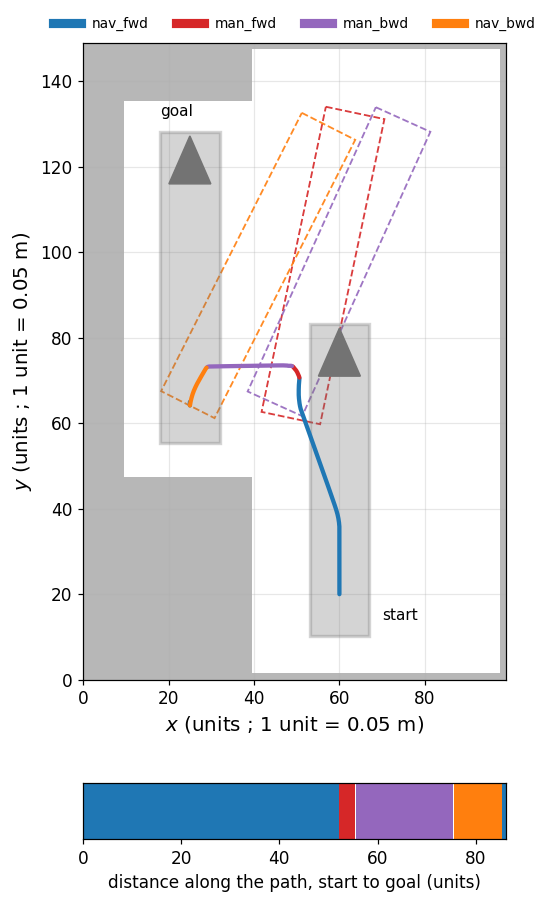

mode       units        heading (deg)
nav_fwd     52.3      90.0 ->   78.1
man_fwd      3.3      78.1 ->   65.7
man_bwd     20.1      65.7 ->   63.2
nav_bwd      9.8      63.2 ->   86.6
nav_fwd      0.8      86.6 ->   90.0
length 86.2 units; share of the length in each mode: nav_fwd 61.6%, man_fwd 3.8%, man_bwd 23.3%, nav_bwd 11.3%


In [7]:
docking = B.load_campaign("docking")["runs"][0]
env = from_benchmark_run(docking, zoom=20.0, n_theta=100)
seed, goal = (list(v) for v in B.endpoints_of(docking))
DOCK_STEERING = 1.05
dock_controls = lambda th, wb, xp: control_set(
    th, wb, delta_f_max=DOCK_STEERING, delta_r_max=DOCK_STEERING, xp=xp, **REFERENCE_COEFFICIENTS)

result = Planner(env, k1=2, k2=3, controls=dock_controls).solve(
    seed + [0], [goal + [0]], free_start_mode=True, geodesic_PastSeed_delay=128)
path = dechatter(result.path(0))[0]
path, _ = close_start(path, seed, env, env.vehicle.wheelbase * env.zoom,
                      DOCK_STEERING, DOCK_STEERING)
s = path[:, 3].round().astype(int)
arc = np.r_[0, np.cumsum(np.hypot(*np.diff(path[:, :2], axis=0).T))]
cuts = np.r_[0, np.flatnonzero(np.diff(s)) + 1, len(s)]      # where each run of a mode starts

fig = plt.figure(figsize=(6.4, 9.4))
grid = fig.add_gridspec(2, 1, height_ratios=[8.0, 0.7], hspace=0.30)
ax, bar = fig.add_subplot(grid[0]), fig.add_subplot(grid[1])
draw_map(ax, env)
# The footprint where each mode takes over, in the colour of that mode,
# for the runs longer than one unit.
for i, j in zip(cuts[1:-1], cuts[2:]):
    if arc[min(j, len(arc) - 1)] - arc[i] > 1.0:
        draw_footprints(ax, path[[i]], env.vehicle, env.zoom, n=1,
                        color=STATE_COLORS[SOLVER_ORDER[s[i]]])
# Start and goal in grey: blue and red stand for modes here.
for pose, label, where in ((seed, "start", (70, 14)), (goal, "goal", (18, 132))):
    draw_pose(ax, *pose, env.vehicle, env.zoom, "0.45")
    ax.annotate(label, where, fontsize=10)
draw_path(ax, path, by_state=True, lw=2.8)
for line in ax.get_lines():                        # above the poses
    line.set_zorder(8)
ax.legend(handles=[Line2D([], [], color=STATE_COLORS[n], lw=6, label=n) for n in SOLVER_ORDER],
          ncol=4, fontsize=9, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)

for k, name in enumerate(SOLVER_ORDER):
    bar.fill_between(arc, 0, 1, where=(s == k), color=STATE_COLORS[name], step="post", lw=0)
bar.set_xlim(0, arc[-1]); bar.set_ylim(0, 1); bar.set_yticks([])
bar.set_xlabel("distance along the path, start to goal (units)")
# The bar spans the width of the map.
fig.canvas.draw()
box, b = ax.get_position(), bar.get_position()
bar.set_position([box.x0, b.y0, box.width, b.height])
save(fig, "04_mode_usage"); plt.show()

# The runs of the path, in the order they are driven.
step = np.hypot(*np.diff(path[:, :2], axis=0).T)
print("%-8s %7s %20s" % ("mode", "units", "heading (deg)"))
for i, j in zip(cuts[:-1], cuts[1:]):
    print("%-8s %7.1f %9.1f -> %6.1f"
          % (SOLVER_ORDER[s[i]], step[i:j].sum(), np.degrees(path[i, 2]),
             np.degrees(path[min(j, len(path) - 1), 2])))
print("length %.1f units; share of the length in each mode: %s"
      % (arc[-1], ", ".join("%s %.1f%%" % (n, 100 * step[s[:-1] == k].sum() / arc[-1])
                             for k, n in enumerate(SOLVER_ORDER))))

The vehicle drives up beside the bay in forward navigation, over 52.3 units
(2.6 m), with the heading close to the direction of travel. It then
switches to the manoeuvring modes: a short forward stretch of 3.3 units that
turns it by about 12 degrees, then a crab backwards of 20.1 units (1.0 m),
which carries it sideways into the bay while its heading barely changes.
It completes its entry reversing in navigation, over 9.8 units, turning to
the goal heading, and ends with 0.8 units (4 cm) forward: the goal is given in
forward navigation, as in notebook 5. The path has five runs in four modes,
and each change of mode is paid for.

Notebook 5 solves the same problem at the transition costs of section 3,
$k_1 = 10$ and $k_2 = 50$ (its section 6): the manoeuvring modes then cover 3 %
of the points of the path, against 26 % at $(2, 3)$, and the vehicle reaches
the bay almost entirely in navigation.

---

Previous: [3. Hamiltonian Fast Marching](03_hamiltonian_fast_marching.ipynb)
Next: [5. Precision docking and narrow passages](05_precision_docking.ipynb)